## 🔧  **SETUP**

In [11]:
import os

#  Imposta il percorso della cartella condivisa (aggiorna il nome se diverso) ...
!ls "/kaggle/input/dataset/"
shared_folder = "/kaggle/input/dataset/archive2"

# Controlla se la cartella esiste e spostati al suo interno
if os.path.exists(shared_folder):
    os.chdir(shared_folder)
    print(f"✅ Cartella impostata correttamente:\n{os.getcwd()}")
else:
    print("❌ La cartella dataset non trovata.")


archive2
✅ Cartella impostata correttamente:
/kaggle/input/dataset/archive2


### ⚙️ **Libraries Import**

In [12]:
# Set seed for reproducibility
SEED = 100

# Import necessary libraries
import os

# Set environment variables before importing modules
os.environ['PYTHONHASHSEED'] = str(SEED)
os.environ['MPLCONFIGDIR'] = os.getcwd() + '/configs/'

# Suppress warnings
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
warnings.simplefilter(action='ignore', category=Warning)

# Import necessary modules
import logging
import random
import numpy as np
from pathlib import Path


# Set seeds for random number generators in NumPy and Python
np.random.seed(SEED)
random.seed(SEED)

# Import PyTorch
import torch
torch.manual_seed(SEED)
from torch import nn
from torchsummary import summary
from torch.utils.tensorboard import SummaryWriter
import torchvision
from torchvision.transforms import v2 as transforms
from torch.utils.data import TensorDataset, DataLoader
#!pip install torchview
#from torchview import draw_graph

# Configurazione di TensorBoard e directory
#logs_dir = "tensorboard"
#!pkill -f tensorboard
#%load_ext tensorboard
#!mkdir -p models

if torch.cuda.is_available():
    device = torch.device("cuda")
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = True
else:
    device = torch.device("cpu")

print(f"PyTorch version: {torch.__version__}")
print(f"Device: {device}")

# Import other libraries
import cv2
import copy
import shutil
from itertools import product
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.model_selection import train_test_split
from PIL import Image
import matplotlib.gridspec as gridspec
import requests
from io import BytesIO

# Configure plot display settings
sns.set(font_scale=1.4)
sns.set_style('white')
plt.rc('font', size=14)
%matplotlib inline

PyTorch version: 2.6.0+cu124
Device: cuda


## ⏳ **Data Loading**

In [13]:
#===============================================
#esc+r TO DEACTIVATE CELL, esc+y TO REACTIVATE IT
#===============================================

def pad_image_with_border_mode(img):
    h, w = img.shape[:2]
    dim = max(h, w)
    pad_h = (dim - h) // 2
    pad_w = (dim - w) // 2

    # I bordi sono già in [0,255] perché img arriva da OpenCV
    top_edge = img[0].astype(int)
    bottom_edge = img[-1].astype(int)
    left_edge = img[:, 0].astype(int)
    right_edge = img[:, -1].astype(int)

    edges = np.concatenate([top_edge, bottom_edge, left_edge, right_edge], axis=0)

    # Moda corretta sul range 0-255
    pad_color = [np.bincount(edges[:, c]).argmax() for c in range(3)]
    pad_color = np.array(pad_color, dtype=img.dtype)

    # Canvas riempito con pad_color
    img_padded = np.ones((dim, dim, 3), dtype=img.dtype)
    img_padded[:] = pad_color


    # Inserimento immagine
    img_padded[pad_h:pad_h+h, pad_w:pad_w+w] = img

    return img_padded

In [14]:
def normalize_image(img, standardize=True):

    img = img.astype(np.float32)
    # Se i pixel non sono ancora in [0,1], li scala
    if img.max() > 1.0:
        img = img / 255.0

    if standardize:
        # Media e std ImageNet
        mean = np.array([0.485, 0.456, 0.406])
        std  = np.array([0.229, 0.224, 0.225])
        img = (img - mean) / std

    return img

In [15]:
#===============================================
#esc+r TO DEACTIVATE CELL, esc+y TO REACTIVATE IT
#===============================================
def load_medical_dataset(folder, target_size=(224, 224), standardize=True):
    """
    Carica immagini e mask da una cartella, applicando padding, resize e normalizzazione.
    """
    images = []
    masks = []

    if not os.path.exists(folder):
        print(f"Error: Folder {folder} does not exist.")
        return np.array([]), np.array([])

    img_files = sorted([f for f in os.listdir(folder) if f.startswith('img_') and f.endswith('.png')])
    print(f"Found {len(img_files)} images in {folder}")

    for img_file in img_files:
        mask_file = img_file.replace('img_', 'mask_')
        img_path = os.path.join(folder, img_file)
        mask_path = os.path.join(folder, mask_file)

        if not os.path.exists(mask_path):
            print(f"Warning: Mask not found for {img_file}, skipping...")
            continue

        # Carica immagine e mask
        img = cv2.imread(img_path)
        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
        if img is None or mask is None:
            print(f"Warning: Could not load {img_file} or {mask_file}, skipping...")
            continue

        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        # 1️⃣ Padding veloce
        img = pad_image_with_border_mode(img)

        # 2️⃣ Resize
        img = cv2.resize(img, target_size)

        # 3️⃣ Normalizzazione / standardizzazione
        img = normalize_image(img, standardize=standardize)

        # 4️⃣ Gestione mask: padding nero, resize, [0,1]
        h, w = mask.shape[:2]
        dim = max(h, w)
        pad_h = (dim - h) // 2
        pad_w = (dim - w) // 2
        mask = np.pad(mask, ((pad_h, dim - h - pad_h), (pad_w, dim - w - pad_w)),
                      mode='constant', constant_values=0)
        mask = cv2.resize(mask, target_size, interpolation=cv2.INTER_NEAREST)
        mask = mask / 255.0
        mask = np.expand_dims(mask, axis=-1)

        images.append(img)
        masks.append(mask)

    print(f"Successfully loaded {len(images)} image-mask pairs")
    return np.array(images), np.array(masks)

In [16]:
train_path = './train_data'
test_path = './test_data'
output_folder = '/kaggle/working'  

train_images, train_masks = load_medical_dataset(train_path, standardize=True)
test_images, test_masks = load_medical_dataset(test_path, standardize=True)

Found 1252 images in ./train_data
Successfully loaded 1252 image-mask pairs
Found 954 images in ./test_data
Successfully loaded 954 image-mask pairs


In [17]:
#===============================================
#esc+r TO DEACTIVATE CELL, esc+y TO REACTIVATE IT
#=============================================

# Dopo che il caricamento è finito, salva i dati

# Crea la cartella di output se non esiste
output_folder = '/kaggle/working/'
os.makedirs(output_folder, exist_ok=True)

# Salva i dati come file .npy (formato binario compresso)
print("Saving train images...")
np.save(f'{output_folder}train_images.npy', train_images)

print("Saving train masks...")
np.save(f'{output_folder}train_masks.npy', train_masks)

print("Saving test images...")
np.save(f'{output_folder}test_images.npy', test_images)

print("Saving test masks...")
np.save(f'{output_folder}test_masks.npy', test_masks)

print("\nDataset salvato in /kaggle/working/")
print(f"Train images: {train_images.shape}")
print(f"Train masks: {train_masks.shape}")
print(f"Test images: {test_images.shape}")
print(f"Test masks: {test_masks.shape}")



Saving train images...
Saving train masks...
Saving test images...
Saving test masks...

Dataset salvato in /kaggle/working/
Train images: (1252, 224, 224, 3)
Train masks: (1252, 224, 224, 1)
Test images: (954, 224, 224, 3)
Test masks: (954, 224, 224, 1)


## 🖼️ DATA VISUALIZATION

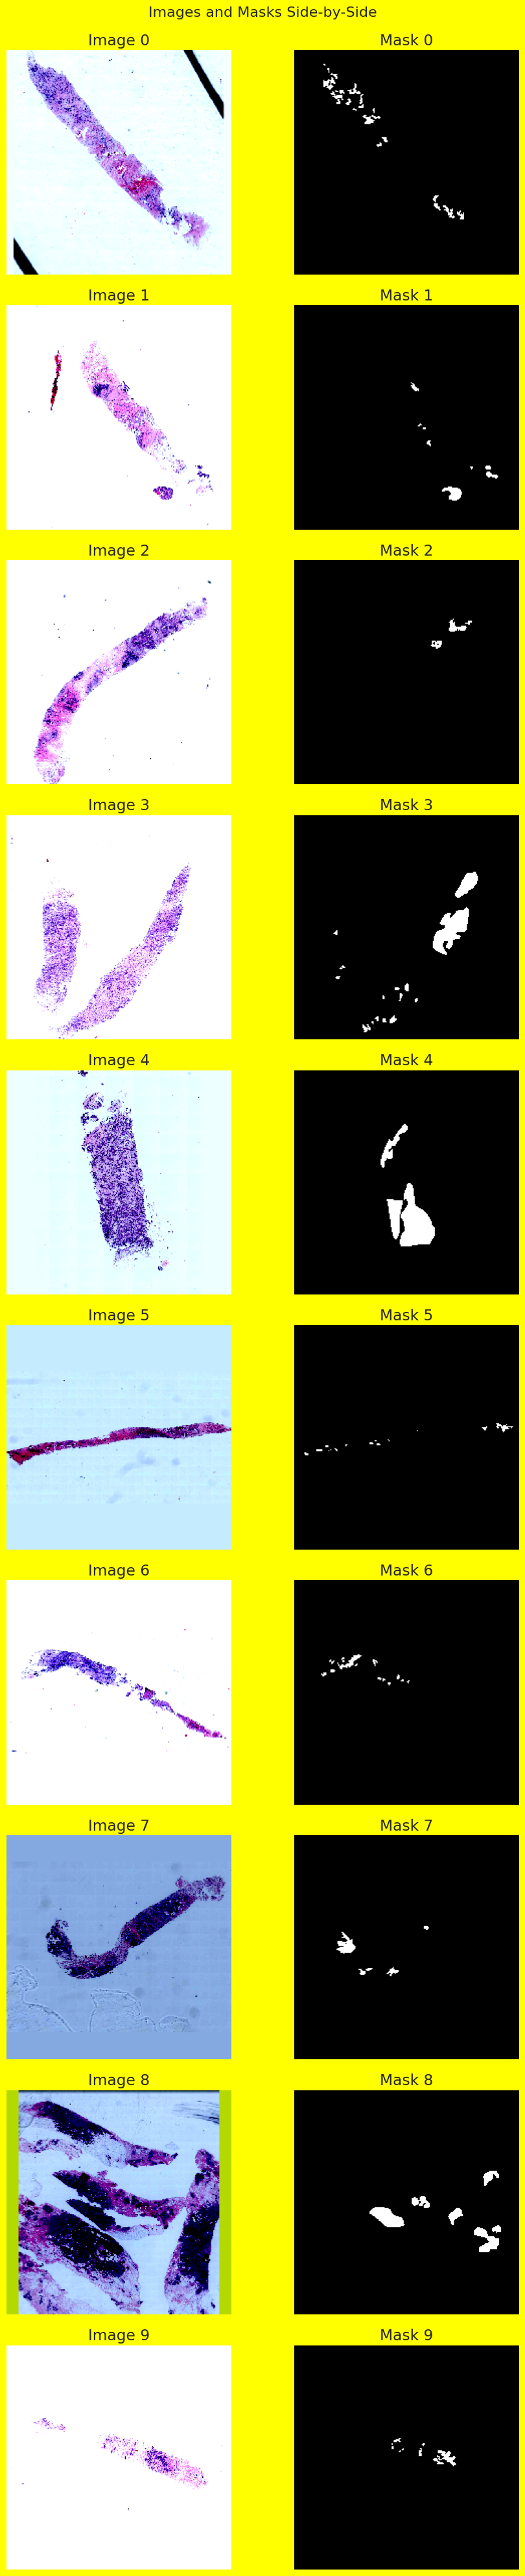

In [19]:
# Number of images to displayyy
num_img = 10
# Display side-by-side comparison (image + mask)
fig, axes = plt.subplots(num_img, 2, figsize=(10, 4*num_img))
fig.patch.set_facecolor('yellow')  # Sfondo giallo per la figura intera
fig.suptitle('Images and Masks Side-by-Side', fontsize=16, y=0.995)
for i in range(num_img):
    # Image on left
    axes[i, 0].imshow(np.clip(train_images[i], 0, 1))
    axes[i, 0].set_title(f'Image {i}')
    axes[i, 0].axis('off')
    axes[i, 0].set_facecolor('yellow')  # Sfondo giallo per i subplot
    
    # Mask on right
    axes[i, 1].imshow(train_masks[i].squeeze(), cmap='gray')
    axes[i, 1].set_title(f'Mask {i}')
    axes[i, 1].axis('off')
    axes[i, 1].set_facecolor('yellow')  # Sfondo giallo per i subplot
plt.tight_layout()
plt.show()